
# Detección y análisis del color dominante en imágenes digitales de naranjas

**Universidad Tecnológica de Pereira**  
**Asignatura:** Procesamiento Digital de Imágenes

## 1. Introducción

El procesamiento digital de imágenes permite extraer información de los objetos representados en una fotografía mediante operaciones sobre sus píxeles.

En este proyecto se desarrolla un algoritmo para detectar una naranja, separar su superficie del fondo y determinar su color RGB promedio y el rango RGB predominante.

Se utilizan técnicas clásicas como filtrado espacial, umbralización, segmentación en HSV, operaciones morfológicas, detección de contornos y cuantización de colores.

### Objetivo general

Desarrollar un algoritmo en Python que permita identificar el contorno de una naranja y determinar su color RGB promedio y el rango de color más frecuente a partir de imágenes digitales.

### Objetivos específicos

1. Segmentar la región correspondiente a la fruta mediante técnicas de procesamiento digital de imágenes.
2. Identificar el contorno y establecer la región de interés (ROI).
3. Calcular el color RGB promedio y determinar el rango RGB dominante.
4. Representar visualmente la fruta utilizando su color predominante.
5. Evaluar el funcionamiento del algoritmo mediante fotografías con diferentes tonalidades y condiciones de captura.

### Alcance

El algoritmo procesa fotografías que contienen una naranja individual, principalmente sobre fondos claros. Se evalúa su comportamiento ante variaciones de color, iluminación y presencia de sombras.

El sistema no determina automáticamente la madurez ni el estado sanitario de la fruta. Su finalidad es analizar el color visible en las imágenes digitales.



## 2. Conjunto de imágenes y metodología

Se utilizaron **50 fotografías** distribuidas en dos conjuntos:

- **Desarrollo (5 imágenes):** utilizadas para construir y ajustar el algoritmo.
- **Evaluación (45 imágenes):** utilizadas para comprobar el funcionamiento del procedimiento con parámetros constantes.

Las imágenes incluyen naranjas amarillentas, anaranjadas y verdes, además de fotografías con sombras y fondos de mayor complejidad.

Las fotografías proceden principalmente de un conjunto de datos público alojado en Mendeley Data, complementado con imágenes seleccionadas para el desarrollo.

**Fuente principal:** [Dataset de naranjas — Mendeley Data](https://data.mendeley.com/datasets/zk4hzhtcdd/2)

### Configuración del procesamiento

| Parámetro | Valor |
|---|---|
| Lenguaje | Python |
| Biblioteca principal | OpenCV |
| Dimensión máxima | 800 píxeles por lado |
| Filtrado | Gaussiano 5 × 5 |
| Segmentación | Canal de saturación HSV |
| Umbral de saturación | 50 |
| Morfología | Cierre con elemento elíptico 5 × 5 |
| Contornos | Mayor contorno exterior |
| Análisis de color | RGB |
| Cuantización | Intervalos de 32 niveles por canal |

Los parámetros se establecieron durante el desarrollo y se mantuvieron constantes en el conjunto de evaluación.


In [57]:
# --------------------------------------------------
# 1. IMPORTACIÓN DE BIBLIOTECAS Y CONFIGURACIÓN
# --------------------------------------------------

from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Path.cwd() obtiene el directorio de trabajo actual.
# El notebook debe ejecutarse desde la carpeta raíz del proyecto.
BASE_DIR = Path.cwd()

# Carpeta con las fotografías utilizadas para desarrollar el algoritmo.
RUTA_DESARROLLO = BASE_DIR / "dataset" / "desarrollo"

# Carpeta con las 45 imágenes reservadas para evaluación.
RUTA_EVALUACION = BASE_DIR / "dataset" / "evaluacion"

# Carpeta donde guardaremos tablas y figuras.
RUTA_RESULTADOS = BASE_DIR / "resultados"
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Fotografía utilizada para explicar paso a paso el procesamiento.
RUTA_IMAGEN = RUTA_DESARROLLO / "naranja01.jpg"

# Parámetros establecidos durante el desarrollo.
TAMANO_MAXIMO = 800
UMBRAL_S = 50
INTERVALO_RGB = 32

# Verificamos que existan las carpetas y la imagen de ejemplo.
if not RUTA_IMAGEN.is_file():
    raise FileNotFoundError(
        f"No se encontró la imagen de ejemplo: {RUTA_IMAGEN}"
    )

if not RUTA_EVALUACION.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de evaluación: {RUTA_EVALUACION}"
    )

print("Proyecto:", BASE_DIR)
print("OpenCV:", cv2.__version__)
print("Imagen de ejemplo:", RUTA_IMAGEN.name)
print("Configuración inicial correcta.")


Proyecto: d:\SistemasUniversidad\sistemas8\ProcDImagenes\deteccion_colores_naranjas
OpenCV: 5.0.0
Imagen de ejemplo: naranja01.jpg
Configuración inicial correcta.



## 3. Lectura y representación de la imagen digital

Una imagen digital en color se representa mediante una matriz tridimensional de dimensiones `(alto, ancho, 3)`. Cada píxel almacena tres componentes correspondientes a los canales rojo, verde y azul (RGB).

En imágenes de 8 bits por canal, cada componente tiene valores entre 0 y 255.

OpenCV utiliza habitualmente el orden BGR al leer imágenes, por lo que es necesario convertirlas a RGB para visualizarlas correctamente con Matplotlib y realizar el análisis de color.

Para reducir el costo computacional, se redimensionan las imágenes cuyo lado mayor supera los 800 píxeles, conservando su proporción. Las fotografías originales no se modifican.


Resolución original: 2048 x 2048
Resolución de procesamiento: 800 x 800
Número de canales: 3
Tipo de datos: uint8
Píxel central RGB: [248 154   0]


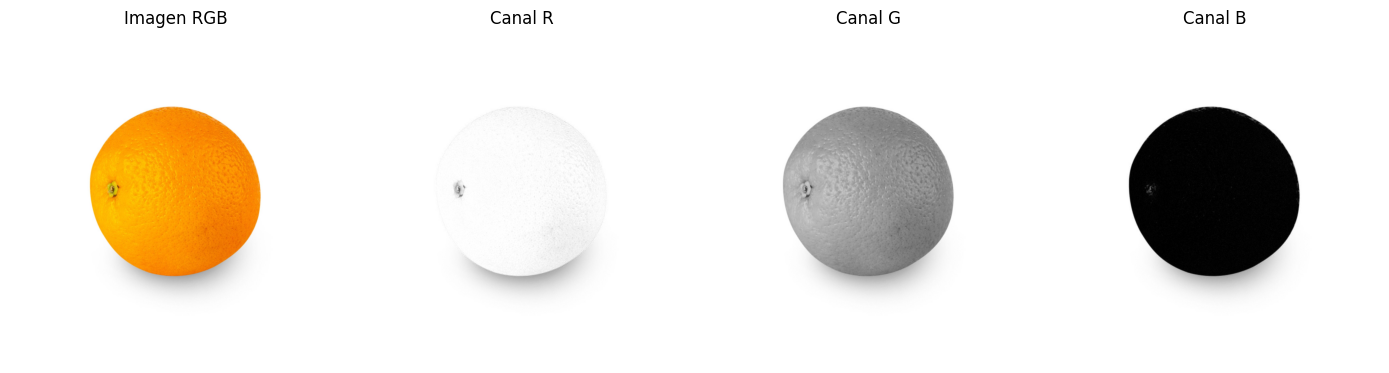

In [58]:

# --------------------------------------------------
# 3. LECTURA Y REPRESENTACIÓN DE LA IMAGEN DIGITAL
# --------------------------------------------------

# imread() lee la fotografía y devuelve una matriz NumPy.
# OpenCV almacena sus canales en orden BGR.
imagen_bgr = cv2.imread(str(RUTA_IMAGEN))

if imagen_bgr is None:
    raise ValueError("No fue posible leer la fotografía.")

# Convertimos BGR a RGB para interpretar correctamente los colores.
imagen_rgb_original = cv2.cvtColor(
    imagen_bgr, cv2.COLOR_BGR2RGB
)

# Obtenemos el alto, ancho y número de canales.
alto_original, ancho_original, canales = imagen_rgb_original.shape

# Calculamos un factor de escala que no aumente la resolución.
escala = min(
    1.0,
    TAMANO_MAXIMO / max(alto_original, ancho_original)
)

# resize() modifica las dimensiones de la matriz.
# INTER_AREA es adecuado para reducir imágenes.
if escala < 1:
    imagen_rgb = cv2.resize(
        imagen_rgb_original,
        None,
        fx=escala,
        fy=escala,
        interpolation=cv2.INTER_AREA
    )
else:
    imagen_rgb = imagen_rgb_original.copy()

alto, ancho = imagen_rgb.shape[:2]

print(f"Resolución original: {ancho_original} x {alto_original}")
print(f"Resolución de procesamiento: {ancho} x {alto}")
print(f"Número de canales: {canales}")
print(f"Tipo de datos: {imagen_rgb.dtype}")
print(f"Píxel central RGB: {imagen_rgb[alto//2, ancho//2]}")

# Extraemos los canales individuales de la imagen.
# Cada canal es una matriz bidimensional.
R, G, B = cv2.split(imagen_rgb)

# Mostramos la imagen y los tres canales en escala de grises.
fig, ax = plt.subplots(1, 4, figsize=(14, 4))

imagenes = [imagen_rgb, R, G, B]
titulos = ["Imagen RGB", "Canal R", "Canal G", "Canal B"]

for i in range(4):
    if i == 0:
        ax[i].imshow(imagenes[i])
    else:
        ax[i].imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)

    ax[i].set_title(titulos[i])
    ax[i].axis("off")

plt.tight_layout()
plt.show()



## 4. Preprocesamiento y segmentación de la fruta

El preprocesamiento prepara la imagen para facilitar la identificación del objeto.

**Filtrado gaussiano:** es un filtro espacial pasa-bajos que suaviza pequeñas variaciones de intensidad mediante un promedio ponderado de los píxeles vecinos. Se utiliza un núcleo de 5 × 5.

**Escala de grises:** transforma los tres canales RGB en uno de intensidad, permitiendo realizar una umbralización basada en la luminosidad.

**Umbralización:** clasifica los píxeles según un valor límite y genera una máscara binaria.

Inicialmente se compara la umbralización inversa en escala de grises con la segmentación basada en el canal de saturación (S) del espacio HSV.

Se utiliza HSV porque permite separar el tono, la saturación y la luminosidad. En nuestras fotografías, la cáscara suele presentar mayor saturación que el fondo blanco.

La comparación permite justificar la elección del método de segmentación.


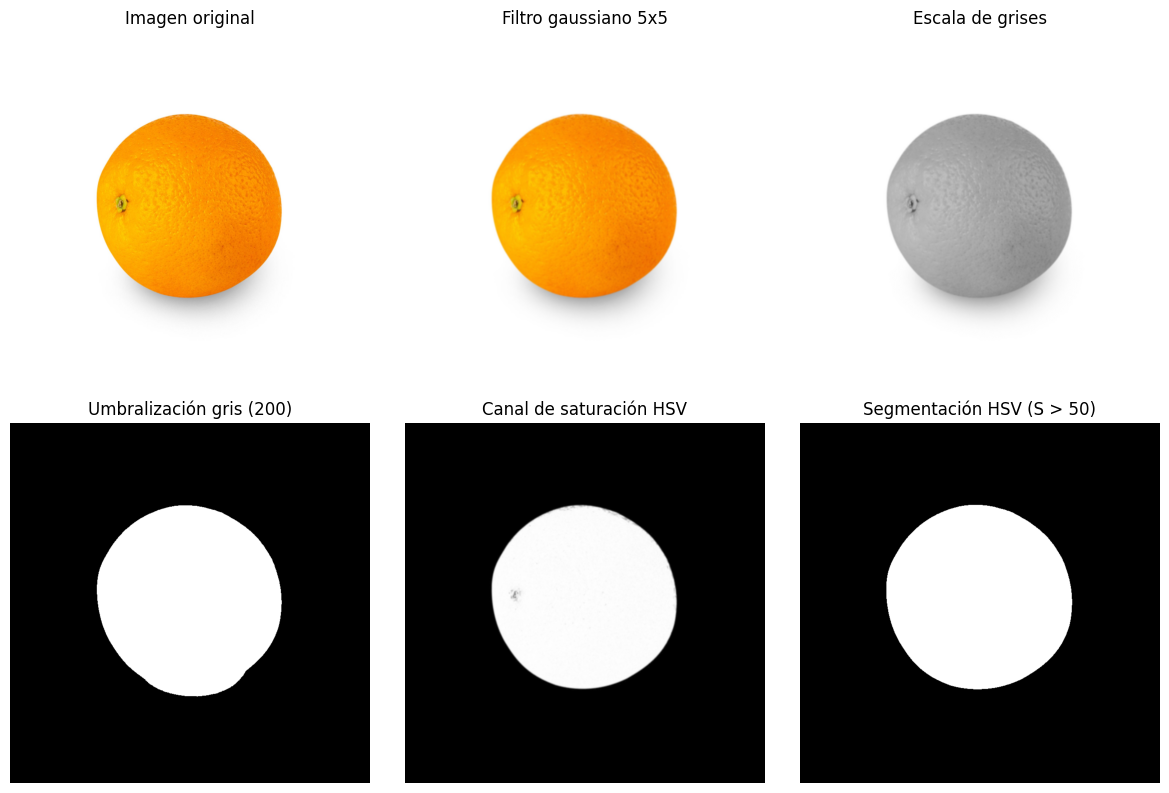

In [59]:

# --------------------------------------------------
# 4. PREPROCESAMIENTO Y COMPARACIÓN DE SEGMENTACIÓN
# --------------------------------------------------

# 1. FILTRADO GAUSSIANO
# GaussianBlur() aplica un promedio ponderado de píxeles vecinos.
# El núcleo 5x5 suaviza pequeñas variaciones y reduce ruido.
# El valor sigma=0 permite que OpenCV lo calcule automáticamente.
imagen_suavizada = cv2.GaussianBlur(
    imagen_rgb, (5, 5), 0
)

# 2. CONVERSIÓN A ESCALA DE GRISES
# cvtColor() transforma los tres canales RGB en uno de intensidad.
imagen_gris = cv2.cvtColor(
    imagen_suavizada, cv2.COLOR_RGB2GRAY
)

# 3. UMBRALIZACIÓN EN ESCALA DE GRISES
# THRESH_BINARY_INV asigna 255 a intensidades <= 200 y 0 al resto.
# Se incluye como método de comparación, no como solución definitiva.
_, mascara_gris = cv2.threshold(
    imagen_gris, 200, 255, cv2.THRESH_BINARY_INV
)

# 4. CONVERSIÓN AL ESPACIO HSV
# H representa el tono, S la saturación y V la luminosidad.
imagen_hsv = cv2.cvtColor(
    imagen_suavizada, cv2.COLOR_RGB2HSV
)

# Extraemos el canal S (índice 1).
# En OpenCV, para imágenes HSV de 8 bits, S varía entre 0 y 255.
saturacion = imagen_hsv[:, :, 1]

# 5. UMBRALIZACIÓN SOBRE LA SATURACIÓN
# THRESH_BINARY asigna 255 cuando S > 50 y 0 en caso contrario.
# Esta será nuestra técnica principal de segmentación.
_, mascara_hsv = cv2.threshold(
    saturacion, UMBRAL_S, 255, cv2.THRESH_BINARY
)

# 6. VISUALIZACIÓN COMPARATIVA
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

visualizaciones = [
    (imagen_rgb, "Imagen original", None),
    (imagen_suavizada, "Filtro gaussiano 5x5", None),
    (imagen_gris, "Escala de grises", "gray"),
    (mascara_gris, "Umbralización gris (200)", "gray"),
    (saturacion, "Canal de saturación HSV", "gray"),
    (mascara_hsv, "Segmentación HSV (S > 50)", "gray")
]

for eje, (imagen, titulo, mapa_color) in zip(
    ax.flat, visualizaciones
):
    if mapa_color is None:
        eje.imshow(imagen)
    else:
        eje.imshow(imagen, cmap=mapa_color, vmin=0, vmax=255)

    eje.set_title(titulo)
    eje.axis("off")

plt.tight_layout()
plt.show()



## 5. Operaciones morfológicas y detección de contornos

Las operaciones morfológicas permiten modificar la forma de las regiones de una imagen binaria mediante un elemento estructurante o *kernel*.

En nuestra máscara, los píxeles blancos (255) representan las regiones detectadas y los negros (0) representan el fondo.

Las principales operaciones son:

- **Erosión:** reduce las regiones blancas y puede eliminar pequeños objetos aislados.
- **Dilatación:** expande las regiones blancas y puede conectar regiones cercanas.
- **Apertura:** aplica erosión seguida de dilatación. Es útil para eliminar pequeñas regiones blancas.
- **Cierre:** aplica dilatación seguida de erosión. Es útil para cerrar pequeñas discontinuidades y rellenar huecos pequeños.

Para el algoritmo definitivo se utiliza un **cierre morfológico con un elemento estructurante elíptico de 5 × 5**, con el propósito de mejorar la continuidad de la máscara.

Posteriormente, se identifican los contornos exteriores y se selecciona el de mayor área, bajo el supuesto de que la naranja es el objeto principal de la fotografía.


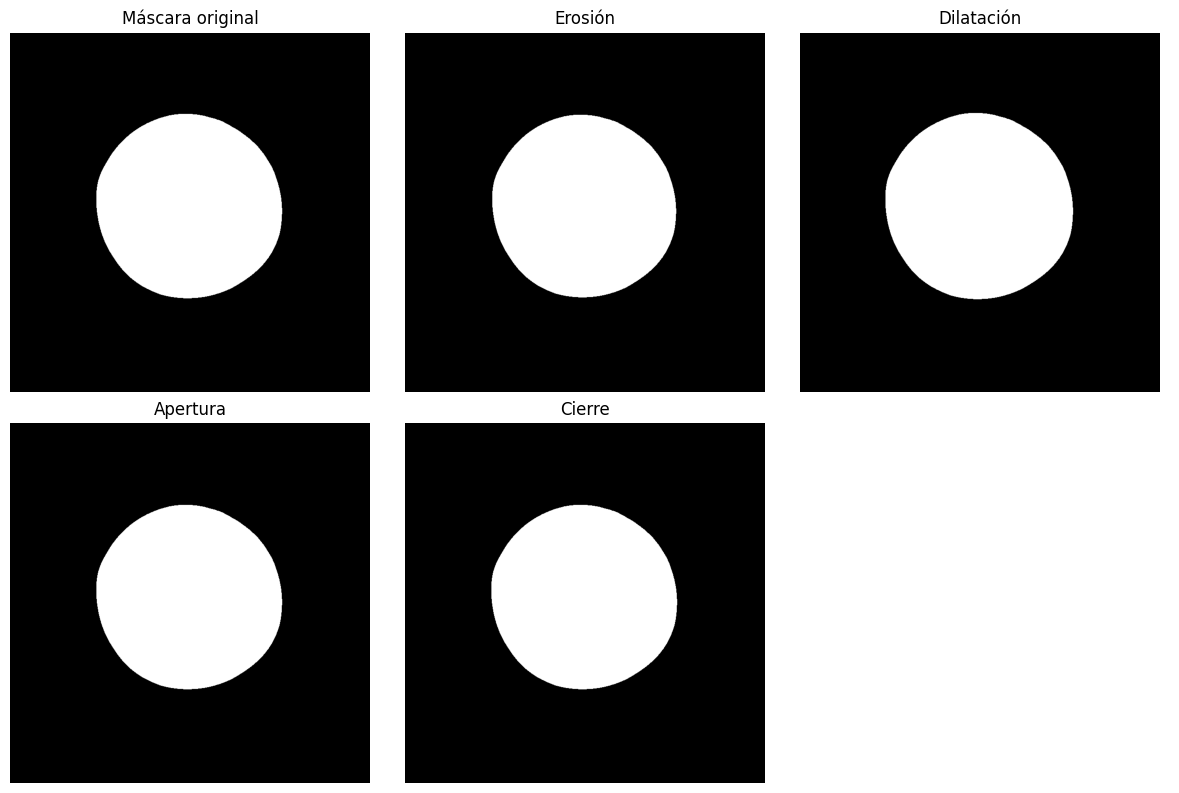

Elemento estructurante utilizado:
[[0 0 1 0 0]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [0 0 1 0 0]]


In [60]:

# --------------------------------------------------
# 5. OPERACIONES MORFOLÓGICAS
# --------------------------------------------------

# Creamos un elemento estructurante de forma elíptica.
# Sus dimensiones son de 5 x 5 píxeles.
kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

# EROSIÓN:
# Reduce las regiones blancas de la máscara.
mascara_erosion = cv2.erode(
    mascara_hsv, kernel, iterations=1
)

# DILATACIÓN:
# Expande las regiones blancas de la máscara.
mascara_dilatacion = cv2.dilate(
    mascara_hsv, kernel, iterations=1
)

# APERTURA:
# Primero erosiona y después dilata.
# Puede eliminar pequeñas regiones blancas aisladas.
mascara_apertura = cv2.morphologyEx(
    mascara_hsv, cv2.MORPH_OPEN, kernel
)

# CIERRE:
# Primero dilata y después erosiona.
# Puede cerrar discontinuidades y huecos pequeños.
# ESTA es la operación usada en el algoritmo definitivo.
mascara_cierre = cv2.morphologyEx(
    mascara_hsv, cv2.MORPH_CLOSE, kernel
)

# Comparación visual de las operaciones.
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

comparaciones = [
    (mascara_hsv, "Máscara original"),
    (mascara_erosion, "Erosión"),
    (mascara_dilatacion, "Dilatación"),
    (mascara_apertura, "Apertura"),
    (mascara_cierre, "Cierre")
]

for eje, (imagen, titulo) in zip(ax.flat, comparaciones):
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    eje.set_title(titulo)
    eje.axis("off")

# Ocultamos el espacio sobrante.
ax.flat[-1].axis("off")

plt.tight_layout()
plt.show()

print("Elemento estructurante utilizado:")
print(kernel)


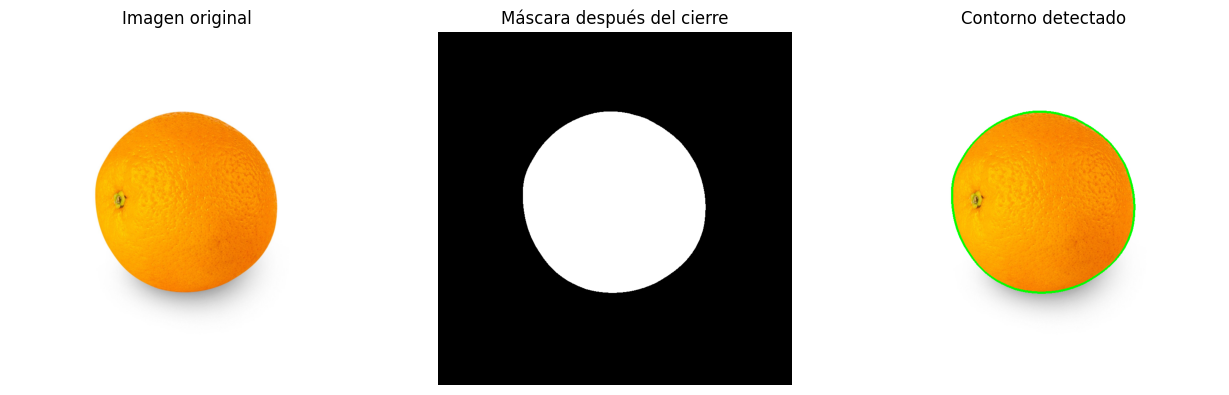

Contornos exteriores encontrados: 1
Área del contorno principal: 132079 píxeles²


In [61]:

# --------------------------------------------------
# 5.1. DETECCIÓN DEL CONTORNO DE LA FRUTA
# --------------------------------------------------

# findContours() identifica los límites de las regiones blancas.
#
# RETR_EXTERNAL: recupera solamente los contornos exteriores.
# CHAIN_APPROX_SIMPLE: reduce puntos redundantes del contorno.
contornos, _ = cv2.findContours(
    mascara_cierre,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

if not contornos:
    raise ValueError("No se encontraron contornos en la imagen.")

# Elegimos el contorno de mayor área.
# Suponemos que la naranja es el objeto principal.
contorno_principal = max(
    contornos,
    key=cv2.contourArea
)

# Calculamos el área del contorno en píxeles cuadrados.
area_contorno = cv2.contourArea(contorno_principal)

# Copiamos la imagen para dibujar sin modificar la original.
imagen_contorno = imagen_rgb.copy()

# Dibujamos el contorno en color verde.
# -1: dibuja el único contorno de la lista.
# (0, 255, 0): verde, porque la imagen está en RGB.
# 3: grosor de la línea.
cv2.drawContours(
    imagen_contorno,
    [contorno_principal],
    -1,
    (0, 255, 0),
    3
)

# Mostramos la máscara y el resultado.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(mascara_cierre, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Máscara después del cierre")

ax[2].imshow(imagen_contorno)
ax[2].set_title("Contorno detectado")

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Contornos exteriores encontrados: {len(contornos)}")
print(f"Área del contorno principal: {area_contorno:.0f} píxeles²")



## 6. Región de interés y análisis del color RGB

Una vez identificado el contorno principal, se construye una **región de interés (ROI)** que contiene los píxeles de la fruta.

Para ello se crea una máscara binaria del mismo tamaño que la imagen y se rellena el interior del contorno seleccionado. Los píxeles blancos representan la región que será analizada.

### Color RGB promedio

Se calcula la media aritmética de cada canal RGB utilizando todos los píxeles de la ROI. Este valor resume el color general de la región segmentada.

### Rango RGB dominante

Para identificar los colores más frecuentes se utiliza una cuantización RGB con intervalos de 32 niveles por canal.

Cada canal de 8 bits se divide en ocho intervalos, obteniendo 512 combinaciones posibles de rangos RGB.

Se identifica la combinación que contiene más píxeles y se calcula su frecuencia relativa. Después se obtiene un color representativo promediando los píxeles que pertenecen a ese intervalo.

El porcentaje dominante representa la proporción de píxeles incluidos en el intervalo RGB más frecuente, no la precisión del algoritmo ni el porcentaje de superficie que una persona percibe como un determinado color.


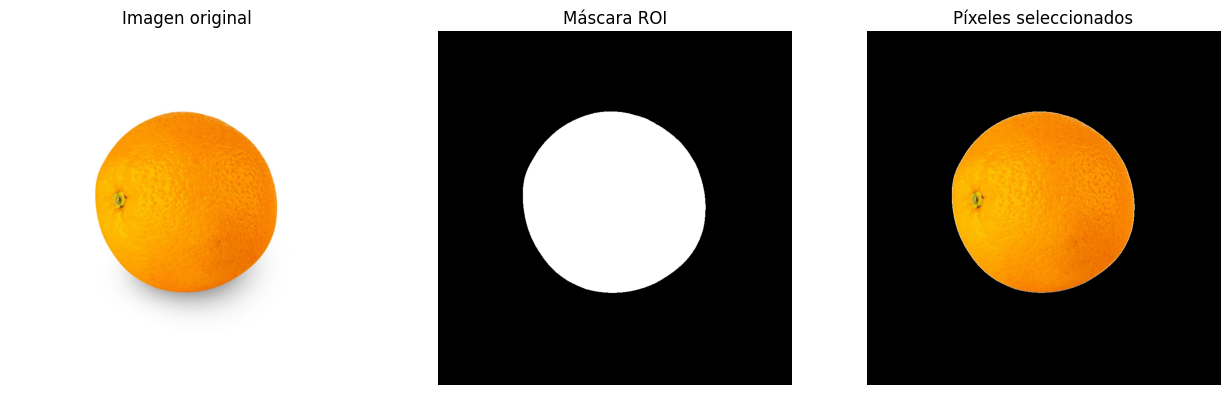

Píxeles de la ROI: 132,660
RGB promedio: [249.32 152.19   5.27]


In [62]:

# --------------------------------------------------
# 6.1. CREACIÓN DE LA ROI Y CÁLCULO DEL RGB PROMEDIO
# --------------------------------------------------

# Creamos una máscara negra con las mismas dimensiones
# espaciales de la imagen RGB.
mascara_roi = np.zeros(
    imagen_rgb.shape[:2],
    dtype=np.uint8
)

# Rellenamos de blanco el interior del contorno principal.
# FILLED indica que se dibuje la región completa.
cv2.drawContours(
    mascara_roi,
    [contorno_principal],
    -1,
    255,
    cv2.FILLED
)

# bitwise_and conserva la imagen donde la máscara vale 255.
# Los píxeles externos quedan negros.
imagen_roi = cv2.bitwise_and(
    imagen_rgb,
    imagen_rgb,
    mask=mascara_roi
)

# Seleccionamos solo los píxeles pertenecientes a la fruta.
# El resultado es una matriz con una fila por píxel
# y tres columnas: R, G y B.
pixeles_roi = imagen_rgb[mascara_roi > 0]

# Calculamos la media de cada canal.
# axis=0 significa calcular la media por columna.
rgb_promedio = np.mean(pixeles_roi, axis=0)

# Visualización.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(mascara_roi, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Máscara ROI")

ax[2].imshow(imagen_roi)
ax[2].set_title("Píxeles seleccionados")

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()

print(f"Píxeles de la ROI: {len(pixeles_roi):,}")
print(f"RGB promedio: {np.round(rgb_promedio, 2)}")


In [63]:

# --------------------------------------------------
# 6.2. CUANTIZACIÓN Y COLOR RGB DOMINANTE
# --------------------------------------------------

# Dividimos cada canal RGB en intervalos de 32 niveles.
# astype(int32) facilita trabajar con valores enteros.
#
# Ejemplo: RGB (250, 150, 10) -> grupo (7, 4, 0).
grupos_rgb = pixeles_roi.astype(np.int32) // INTERVALO_RGB

# np.unique() identifica las combinaciones RGB existentes.
# axis=0 compara filas completas: grupos (R, G, B).
# return_counts=True devuelve la frecuencia de cada grupo.
grupos_unicos, frecuencias = np.unique(
    grupos_rgb,
    axis=0,
    return_counts=True
)

# Identificamos el grupo más frecuente.
indice_dominante = np.argmax(frecuencias)

grupo_dominante = grupos_unicos[indice_dominante]
frecuencia_dominante = frecuencias[indice_dominante]

# Calculamos los límites RGB del intervalo dominante.
rango_inferior = grupo_dominante * INTERVALO_RGB

rango_superior = np.minimum(
    rango_inferior + INTERVALO_RGB - 1,
    255
)

# Identificamos cuáles píxeles pertenecen a ese grupo.
seleccion_dominante = np.all(
    grupos_rgb == grupo_dominante,
    axis=1
)

# Calculamos un color representativo del intervalo dominante.
# Promediamos únicamente los píxeles incluidos en ese grupo.
rgb_dominante = np.mean(
    pixeles_roi[seleccion_dominante],
    axis=0
)

# Porcentaje de píxeles en el intervalo más frecuente.
porcentaje_dominante = (
    frecuencia_dominante / len(pixeles_roi)
) * 100

print("Grupo dominante:", grupo_dominante)
print("Rango RGB inferior:", rango_inferior)
print("Rango RGB superior:", rango_superior)
print("Frecuencia dominante:", frecuencia_dominante)
print(f"Porcentaje dominante: {porcentaje_dominante:.2f} %")
print("RGB representativo:", np.round(rgb_dominante, 2))


Grupo dominante: [7 4 0]
Rango RGB inferior: [224 128   0]
Rango RGB superior: [255 159  31]
Frecuencia dominante: 72431
Porcentaje dominante: 54.60 %
RGB representativo: [250.11 143.7    2.93]


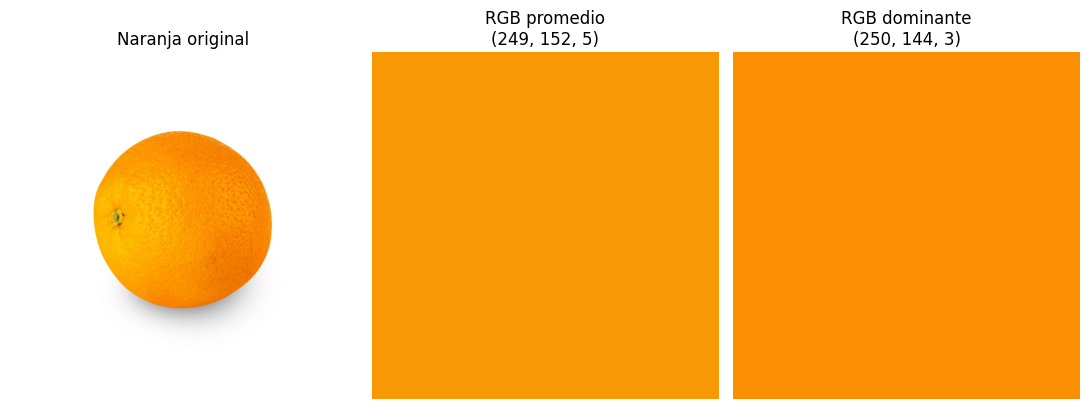

In [64]:

# --------------------------------------------------
# 6.3. VISUALIZACIÓN DE LOS COLORES CALCULADOS
# --------------------------------------------------

# Convertimos los valores RGB a números entre 0 y 1,
# formato que Matplotlib acepta para definir colores.
color_promedio = rgb_promedio / 255
color_dominante = rgb_dominante / 255

fig, ax = plt.subplots(1, 3, figsize=(11, 4))

# Fotografía original.
ax[0].imshow(imagen_rgb)
ax[0].set_title("Naranja original")

# Muestra del color promedio.
ax[1].imshow(
    np.ones((100, 100, 3)) * color_promedio
)
ax[1].set_title(
    f"RGB promedio\n"
    f"{tuple(int(round(v)) for v in rgb_promedio)}"
)

# Muestra del color dominante.
ax[2].imshow(
    np.ones((100, 100, 3)) * color_dominante
)
ax[2].set_title(
    f"RGB dominante\n"
    f"{tuple(int(round(v)) for v in rgb_dominante)}"
)

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()



## 7. Representación visual del color dominante

Para visualizar el resultado del análisis, se genera una copia de la fotografía y se reemplazan los píxeles de la región de interés por el color RGB dominante.

La operación conserva las dimensiones originales de la imagen procesada y modifica únicamente los píxeles incluidos en la máscara ROI.

De esta manera, la superficie de la fruta aparece representada mediante un color uniforme, mientras el fondo permanece sin cambios.

Esta representación permite observar el color predominante estimado y verificar visualmente la región segmentada.


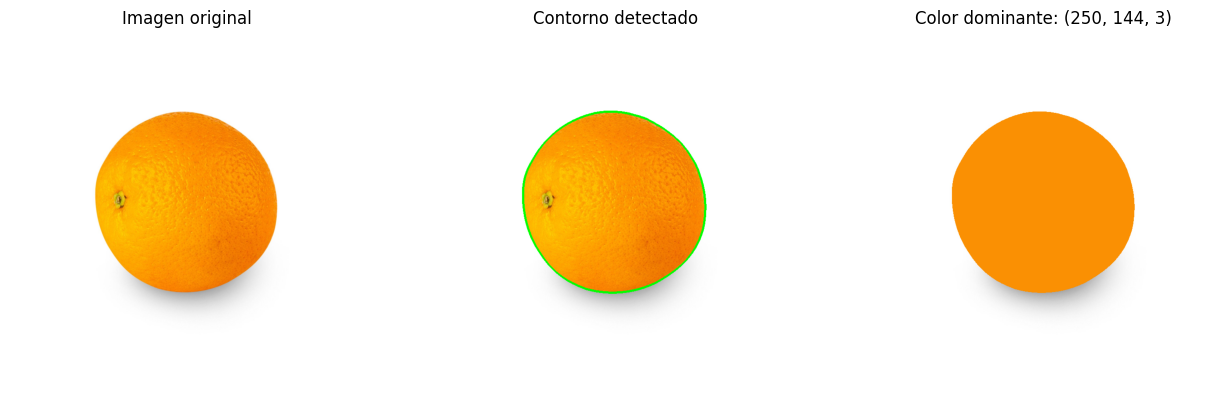

In [66]:

# --------------------------------------------------
# 7. REPINTADO DE LA NARANJA CON SU COLOR DOMINANTE
# --------------------------------------------------

# Creamos una copia para conservar la fotografía original.
imagen_repintada = imagen_rgb.copy()

# Redondeamos el RGB dominante y lo convertimos a uint8.
# Una imagen de 8 bits requiere valores enteros entre 0 y 255.
rgb_dominante_entero = np.round(
    rgb_dominante
).astype(np.uint8)

# Reemplazamos únicamente los píxeles de la ROI.
# Los píxeles del fondo permanecen sin modificaciones.
imagen_repintada[mascara_roi > 0] = rgb_dominante_entero

# Visualizamos el resultado.
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(imagen_rgb)
ax[0].set_title("Imagen original")

ax[1].imshow(imagen_contorno)
ax[1].set_title("Contorno detectado")

ax[2].imshow(imagen_repintada)
ax[2].set_title(
    "Color dominante: "
    + str(tuple(int(v) for v in rgb_dominante_entero))
)

for eje in ax:
    eje.axis("off")

plt.tight_layout()
plt.show()



## 8. Implementación del algoritmo completo

Se implementa la función `analizar_naranja()`, que integra las operaciones desarrolladas anteriormente.

El procedimiento comprende:

1. Lectura y redimensionamiento de la fotografía.
2. Suavizado mediante filtro gaussiano.
3. Conversión al espacio HSV y umbralización del canal de saturación.
4. Aplicación de cierre morfológico.
5. Detección y selección del contorno exterior de mayor área.
6. Construcción de la región de interés.
7. Cálculo del RGB promedio.
8. Cuantización RGB e identificación del intervalo dominante.
9. Repintado de la región segmentada con su color representativo.

La función devuelve un diccionario con las imágenes procesadas y las mediciones obtenidas, facilitando su reutilización durante la evaluación experimental.


In [67]:

# --------------------------------------------------
# 8. FUNCIÓN PRINCIPAL: ANÁLISIS DE UNA NARANJA
# --------------------------------------------------

def analizar_naranja(
    ruta_imagen,
    umbral_s=UMBRAL_S,
    intervalo_rgb=INTERVALO_RGB
):
    """
    Detecta la región principal de una naranja y calcula
    su RGB promedio y el intervalo RGB dominante.

    Parámetros:
        ruta_imagen: ruta de la fotografía.
        umbral_s: umbral mínimo de saturación HSV.
        intervalo_rgb: amplitud de los intervalos RGB.

    Devuelve:
        Un diccionario con imágenes y resultados del análisis.
    """

    if not 1 <= intervalo_rgb <= 256:
        raise ValueError("El intervalo RGB debe estar entre 1 y 256.")

    # --------------------------------------------------
    # 1. LECTURA Y REDIMENSIONAMIENTO
    # --------------------------------------------------

    ruta_imagen = Path(ruta_imagen)

    imagen_bgr = cv2.imread(str(ruta_imagen))

    if imagen_bgr is None:
        raise ValueError(
            f"No fue posible leer la imagen: {ruta_imagen}"
        )

    # OpenCV lee en BGR; convertimos a RGB.
    imagen_rgb = cv2.cvtColor(
        imagen_bgr, cv2.COLOR_BGR2RGB
    )

    alto, ancho = imagen_rgb.shape[:2]

    # Reducimos imágenes grandes manteniendo la proporción.
    escala = min(
        1.0,
        TAMANO_MAXIMO / max(alto, ancho)
    )

    if escala < 1:
        imagen_rgb = cv2.resize(
            imagen_rgb,
            None,
            fx=escala,
            fy=escala,
            interpolation=cv2.INTER_AREA
        )

    # --------------------------------------------------
    # 2. FILTRADO Y SEGMENTACIÓN HSV
    # --------------------------------------------------

    # El filtro gaussiano suaviza pequeñas variaciones.
    imagen_suavizada = cv2.GaussianBlur(
        imagen_rgb, (5, 5), 0
    )

    # Transformamos RGB a HSV para analizar la saturación.
    imagen_hsv = cv2.cvtColor(
        imagen_suavizada,
        cv2.COLOR_RGB2HSV
    )

    saturacion = imagen_hsv[:, :, 1]

    # Seleccionamos los píxeles con saturación > umbral_s.
    _, mascara_hsv = cv2.threshold(
        saturacion,
        umbral_s,
        255,
        cv2.THRESH_BINARY
    )

    # --------------------------------------------------
    # 3. CIERRE MORFOLÓGICO
    # --------------------------------------------------

    # Elemento estructurante elíptico de 5 x 5.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )

    # El cierre corrige pequeñas discontinuidades.
    mascara_cierre = cv2.morphologyEx(
        mascara_hsv,
        cv2.MORPH_CLOSE,
        kernel
    )

    # --------------------------------------------------
    # 4. DETECCIÓN DEL CONTORNO PRINCIPAL
    # --------------------------------------------------

    # Recuperamos los contornos exteriores.
    contornos, _ = cv2.findContours(
        mascara_cierre,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    if not contornos:
        raise ValueError(
            f"No se encontraron contornos: {ruta_imagen.name}"
        )

    # Seleccionamos el contorno de mayor área.
    contorno_principal = max(
        contornos,
        key=cv2.contourArea
    )

    # Dibujamos el contorno sobre una copia RGB.
    imagen_contorno = imagen_rgb.copy()

    cv2.drawContours(
        imagen_contorno,
        [contorno_principal],
        -1,
        (0, 255, 0),
        3
    )

    # --------------------------------------------------
    # 5. CONSTRUCCIÓN DE LA REGIÓN DE INTERÉS
    # --------------------------------------------------

    # Creamos una máscara negra.
    mascara_roi = np.zeros(
        imagen_rgb.shape[:2],
        dtype=np.uint8
    )

    # Rellenamos el interior del contorno seleccionado.
    cv2.drawContours(
        mascara_roi,
        [contorno_principal],
        -1,
        255,
        cv2.FILLED
    )

    # Extraemos solamente los píxeles seleccionados.
    pixeles_roi = imagen_rgb[mascara_roi > 0]

    if len(pixeles_roi) == 0:
        raise ValueError(
            f"La ROI está vacía: {ruta_imagen.name}"
        )

    # --------------------------------------------------
    # 6. CÁLCULO DEL RGB PROMEDIO
    # --------------------------------------------------

    rgb_promedio = np.mean(
        pixeles_roi,
        axis=0
    )

    # --------------------------------------------------
    # 7. IDENTIFICACIÓN DEL INTERVALO RGB DOMINANTE
    # --------------------------------------------------

    # Agrupamos los colores en intervalos.
    grupos_rgb = (
        pixeles_roi.astype(np.int32) // intervalo_rgb
    )

    # Contamos cuántos píxeles pertenecen a cada grupo.
    grupos_unicos, frecuencias = np.unique(
        grupos_rgb,
        axis=0,
        return_counts=True
    )

    # Encontramos el grupo más frecuente.
    indice_dominante = np.argmax(frecuencias)

    grupo_dominante = grupos_unicos[indice_dominante]
    frecuencia_dominante = frecuencias[indice_dominante]

    # Determinamos los límites RGB del intervalo.
    rango_inferior = grupo_dominante * intervalo_rgb

    rango_superior = np.minimum(
        rango_inferior + intervalo_rgb - 1,
        255
    )

    # Seleccionamos los píxeles del grupo dominante.
    seleccion_dominante = np.all(
        grupos_rgb == grupo_dominante,
        axis=1
    )

    # Obtenemos un RGB representativo de ese grupo.
    rgb_dominante = np.mean(
        pixeles_roi[seleccion_dominante],
        axis=0
    )

    # Calculamos su frecuencia relativa.
    porcentaje_dominante = (
        frecuencia_dominante / len(pixeles_roi)
    ) * 100

    # --------------------------------------------------
    # 8. REPINTADO DE LA FRUTA
    # --------------------------------------------------

    # Trabajamos sobre una copia para conservar la original.
    imagen_repintada = imagen_rgb.copy()

    color_dominante = np.round(
        rgb_dominante
    ).astype(np.uint8)

    # Reemplazamos únicamente los píxeles de la ROI.
    imagen_repintada[mascara_roi > 0] = color_dominante

    # --------------------------------------------------
    # 9. RESULTADOS
    # --------------------------------------------------

    return {
        "nombre": ruta_imagen.name,
        "imagen": imagen_rgb,
        "mascara": mascara_roi,
        "contorno": imagen_contorno,
        "rgb_promedio": rgb_promedio,
        "rgb_dominante": rgb_dominante,
        "rango_inferior": rango_inferior,
        "rango_superior": rango_superior,
        "porcentaje": porcentaje_dominante,
        "pixeles": len(pixeles_roi),
        "repintada": imagen_repintada
    }


In [68]:

# --------------------------------------------------
# 8.1. VERIFICACIÓN DEL ALGORITMO COMPLETO
# --------------------------------------------------

resultado = analizar_naranja(RUTA_IMAGEN)

print("Fotografía:", resultado["nombre"])

print(
    "RGB promedio:",
    np.round(resultado["rgb_promedio"], 2)
)

print(
    "RGB dominante:",
    np.round(resultado["rgb_dominante"], 2)
)

print(
    "Rango inferior:",
    resultado["rango_inferior"]
)

print(
    "Rango superior:",
    resultado["rango_superior"]
)

print(
    f"Porcentaje dominante: {resultado['porcentaje']:.2f} %"
)

print(
    f"Píxeles analizados: {resultado['pixeles']:,}"
)

# Verificación de consistencia con el procesamiento manual.
assert np.allclose(
    resultado["rgb_promedio"],
    rgb_promedio
), "El RGB promedio no coincide."

assert np.allclose(
    resultado["rgb_dominante"],
    rgb_dominante
), "El RGB dominante no coincide."

assert np.isclose(
    resultado["porcentaje"],
    porcentaje_dominante
), "El porcentaje dominante no coincide."

print("\nVerificación correcta: ambos procedimientos coinciden.")


Fotografía: naranja01.jpg
RGB promedio: [249.32 152.19   5.27]
RGB dominante: [250.11 143.7    2.93]
Rango inferior: [224 128   0]
Rango superior: [255 159  31]
Porcentaje dominante: 54.60 %
Píxeles analizados: 132,660

Verificación correcta: ambos procedimientos coinciden.
